# ReviewSense BR — classificação de sentimentos em português

Experimento de classificação de avaliações com **TF-IDF e regressão logística**, comparado a uma referência de classe majoritária. O protocolo inclui preparação dos dados, seleção de hiperparâmetro em validação e avaliação em teste reservado.

**Resultado no teste:** acurácia de **79,18%** e Macro-F1 de **0,7230**, em 19.002 avaliações.

**Dados:** [B2W-Reviews01](https://github.com/americanas-tech/b2w-reviews01), B2W Digital, avaliações de produtos da Americanas coletadas em 2018. Licença: **CC BY-NC-SA 4.0**. Experimento educacional e não comercial.

O domínio avaliado é o de produtos de comércio eletrônico. Os rótulos são aproximações derivadas das notas em estrelas, e não anotações independentes do sentimento textual.


## 1. Ambiente e dependências

O processamento e o treinamento são executados em CPU. A execução registrada utilizou Python 3.13.18 e scikit-learn 1.6.1. As versões das dependências são exportadas em `requirements.txt` junto ao modelo.


In [1]:
%pip -q install pandas numpy scipy scikit-learn matplotlib joblib huggingface_hub


In [2]:
import hashlib
import io
import json
import platform
import shutil
import urllib.request
from importlib.metadata import version
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score,
                             classification_report, f1_score)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline

SEED = 42
LABELS = ['negativo', 'neutro', 'positivo']
OUT = Path('reviewsense_br_export')
OUT.mkdir(exist_ok=True)
print('Python:', platform.python_version())
print('scikit-learn:', version('scikit-learn'))


Python: 3.13.18
scikit-learn: 1.6.1


## 2. Aquisição e inspeção dos dados

A leitura utiliza apenas `review_text` e `overall_rating`, em CSV separado por vírgulas. O SHA-256 registra a identidade do arquivo utilizado.

A base contém 132.373 registros, dos quais 3.275 não possuem texto. Todas as linhas possuem nota. O pacote de resultados não inclui o CSV original nem avaliações individuais.


In [4]:
DATA_URL = 'https://raw.githubusercontent.com/americanas-tech/b2w-reviews01/main/B2W-Reviews01.csv'
with urllib.request.urlopen(DATA_URL, timeout=120) as response:
    raw_bytes = response.read()
dataset_sha256 = hashlib.sha256(raw_bytes).hexdigest()
df = pd.read_csv(io.BytesIO(raw_bytes), sep=',', usecols=['review_text', 'overall_rating'])
raw_rows = len(df)
print('Linhas originais:', raw_rows)
print('Campos:', df.columns.tolist())
print('Valores ausentes:')
print(df.isna().sum())
print('SHA-256:', dataset_sha256)
del raw_bytes


Linhas originais: 132373
Campos: ['overall_rating', 'review_text']
Valores ausentes:
overall_rating       0
review_text       3275
dtype: int64
SHA-256: 821fb0bf9f7230b0fba4e4f9fadd75a66d1a9ff0b1657810791d33007eb2ab38


## 3. Preparação dos dados e definição dos rótulos

| Nota | Classe aproximada |
|---|---|
| 1 ou 2 | negativo |
| 3 | neutro |
| 4 ou 5 | positivo |

O texto recebe normalização Unicode NFKC, padronização de espaços e conversão para minúsculas. Acentos e negações são preservados. Registros sem texto, textos vazios e notas inválidas são excluídos.

Textos normalizados associados a classes diferentes são removidos; em seguida, uma única ocorrência de cada texto restante é mantida. A deduplicação ocorre antes da separação dos conjuntos, evitando cópias exatas entre treino, validação e teste. Quase duplicatas ainda podem permanecer.

A preparação removeu 50 linhas com classes conflitantes e 2.374 cópias repetidas, resultando em **126.674 avaliações**. A classe positiva representa aproximadamente 61,8% dos registros, a negativa 25,7% e a neutra 12,5%.

A nota é usada exclusivamente para construir o rótulo; não é uma variável de entrada do modelo. Notas de três estrelas podem representar sentimentos mistos ou insatisfação, introduzindo ruído na classe neutra.


In [5]:
df['overall_rating'] = pd.to_numeric(df['overall_rating'], errors='coerce')
df = df.dropna(subset=['review_text', 'overall_rating']).copy()
df = df[df['overall_rating'].isin([1, 2, 3, 4, 5])].copy()
df['text'] = (df['review_text'].astype(str).str.normalize('NFKC')
              .str.replace(r'\s+', ' ', regex=True).str.strip().str.lower())
df = df[df['text'].str.len() > 0].copy()
df['label'] = df['overall_rating'].map({1: 'negativo', 2: 'negativo', 3: 'neutro', 4: 'positivo', 5: 'positivo'})
label_counts = df.groupby('text')['label'].nunique()
conflicting_texts = label_counts[label_counts > 1].index
conflicting_rows = int(df['text'].isin(conflicting_texts).sum())
df = df[~df['text'].isin(conflicting_texts)].copy()
before_dedup = len(df)
df = df.drop_duplicates('text')[['text', 'label']].reset_index(drop=True)
print('Linhas com rótulos conflitantes removidas:', conflicting_rows)
print('Cópias repetidas removidas:', before_dedup - len(df))
print('Linhas utilizáveis:', len(df))
display(df['label'].value_counts().rename('quantidade').to_frame())


Linhas com rótulos conflitantes removidas: 50
Cópias repetidas removidas: 2374
Linhas utilizáveis: 126674


,quantidade
label,
positivo,78242
negativo,32593
neutro,15839


## 4. Protocolo experimental

A divisão aleatória estratificada utiliza semente 42 e preserva aproximadamente as proporções das classes em cada conjunto.

| Conjunto | Proporção | Avaliações | Uso |
|---|---:|---:|---|
| Treino | 70% | 88.671 | Aprendizado dos parâmetros |
| Validação | 15% | 19.001 | Seleção do hiperparâmetro C |
| Teste | 15% | 19.002 | Avaliação final |

As verificações de interseção confirmam a ausência de textos normalizados idênticos entre os conjuntos. O protocolo estima desempenho no mesmo corpus; não constitui validação temporal, por produto ou em outro domínio.


In [6]:
train, remaining = train_test_split(df, test_size=0.30, stratify=df['label'], random_state=SEED)
valid, test = train_test_split(remaining, test_size=0.50, stratify=remaining['label'], random_state=SEED)
assert set(train['text']).isdisjoint(valid['text'])
assert set(train['text']).isdisjoint(test['text'])
assert set(valid['text']).isdisjoint(test['text'])
print('Treino:', len(train), '| Validação:', len(valid), '| Teste:', len(test))


Treino: 88671 | Validação: 19001 | Teste: 19002


## 5. Modelo e seleção do hiperparâmetro

Uma `Pipeline` combina `TfidfVectorizer` e `LogisticRegression`. O vocabulário e os pesos de TF-IDF são aprendidos apenas no treino durante a seleção de configuração.

| Componente | Configuração |
|---|---|
| TF-IDF | Unigramas e bigramas, `min_df=3`, até 40.000 atributos, `sublinear_tf=True` |
| Regressão logística | `class_weight='balanced'`, `max_iter=1000`, semente 42 |
| Busca de C | 0,5 e 2,0 |
| Critério de seleção | Maior Macro-F1 na validação |

O Macro-F1 atribui a mesma importância às três classes. Os pesos balanceados aumentam a contribuição relativa das classes menos frequentes na função de treinamento, sem duplicar exemplos.


In [7]:
def build_model(c):
    return Pipeline([
        ('tfidf', TfidfVectorizer(ngram_range=(1, 2), min_df=3,
                                 max_features=40000, sublinear_tf=True, dtype=np.float64)),
        ('classifier', LogisticRegression(C=c, class_weight='balanced', max_iter=1000, random_state=SEED)),
    ])

validation_results = []
for c in [0.5, 2.0]:
    candidate = build_model(c)
    candidate.fit(train['text'], train['label'])
    predicted = candidate.predict(valid['text'])
    score = f1_score(valid['label'], predicted, labels=LABELS, average='macro', zero_division=0)
    validation_results.append({'C': c, 'validation_macro_f1': float(score)})
    print(f'C={c}: Macro-F1 de validação = {score:.4f}')
best_c = max(validation_results, key=lambda result: result['validation_macro_f1'])['C']
print('C escolhido:', best_c)


C=0.5: Macro-F1 de validação = 0.7190
C=2.0: Macro-F1 de validação = 0.7122
C escolhido: 0.5


## 6. Avaliação no conjunto de teste

A configuração selecionada (`C=0.5`) é ajustada novamente em treino + validação, totalizando 107.672 exemplos. O conjunto de teste permanece reservado até a avaliação final.

A referência `DummyClassifier(strategy='most_frequent')` sempre prevê a classe positiva. A comparação utiliza acurácia e Macro-F1, complementadas por precisão, recall, F1 por classe e matriz de confusão. Na matriz, as linhas representam os rótulos de referência e as colunas, as previsões.


,accuracy,macro_f1
dummy,0.617672,0.254552
tfidf_logistic_regression,0.791811,0.723001


              precision    recall  f1-score   support

    negativo       0.85      0.88      0.86      4889
      neutro       0.36      0.59      0.45      2376
    positivo       0.94      0.80      0.86     11737

    accuracy                           0.79     19002
   macro avg       0.71      0.76      0.72     19002
weighted avg       0.84      0.79      0.81     19002



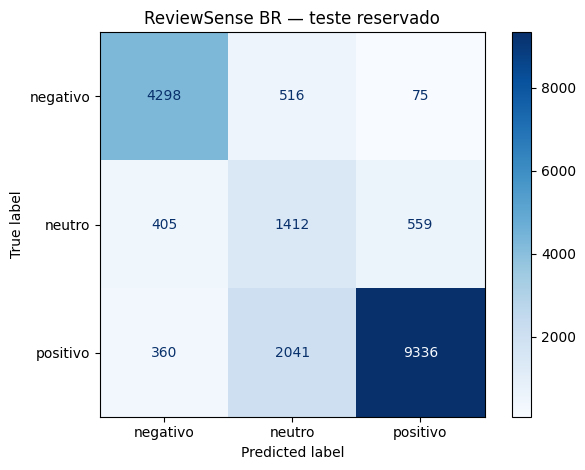

In [8]:
development = pd.concat([train, valid], ignore_index=True)
model = build_model(best_c)
model.fit(development['text'], development['label'])
test_predictions = model.predict(test['text'])

dummy = DummyClassifier(strategy='most_frequent')
dummy.fit(np.zeros((len(development), 1)), development['label'])
dummy_predictions = dummy.predict(np.zeros((len(test), 1)))

def scores(y_true, y_pred):
    return {'accuracy': float(accuracy_score(y_true, y_pred)),
            'macro_f1': float(f1_score(y_true, y_pred, labels=LABELS, average='macro', zero_division=0))}

results = {'dummy': scores(test['label'], dummy_predictions),
           'tfidf_logistic_regression': scores(test['label'], test_predictions)}
display(pd.DataFrame(results).T)
report = classification_report(test['label'], test_predictions, labels=LABELS, output_dict=True, zero_division=0)
print(classification_report(test['label'], test_predictions, labels=LABELS, zero_division=0))
ConfusionMatrixDisplay.from_predictions(test['label'], test_predictions, labels=LABELS, cmap='Blues')
plt.title('ReviewSense BR — teste reservado')
plt.tight_layout()
plt.savefig(OUT / 'confusion_matrix.png', dpi=150)
plt.show()


### Interpretação dos resultados

A configuração `C=0.5` obteve Macro-F1 de 0,7190 na validação, contra 0,7122 para `C=2.0`. No teste, o modelo final alcançou **0,7230 de Macro-F1** e **79,18% de acurácia**, superando a referência majoritária de 0,2546 e 61,77%, respectivamente.

As classes negativa e positiva obtiveram F1 arredondado de 0,86, enquanto a classe neutra atingiu 0,45. A precisão da classe neutra foi de aproximadamente 36%, indicando que muitas previsões dessa classe pertenciam a outras classes de referência. O maior grupo de erros foi o de avaliações positivas previstas como neutras: **2.041 casos**.

O teste teve **3.956 previsões incorretas em 19.002 exemplos**. A proximidade entre os escores de validação e teste é consistente com desempenho semelhante nessas divisões do corpus, mas não demonstra generalização para outros domínios.


## 7. Análise de erros e avaliação qualitativa

As previsões incorretas são agrupadas por classe de referência e classe prevista, sem exibir avaliações individuais. A inspeção qualitativa inicial indicou trechos com sentimentos mistos e elogios classificados como neutros; como os textos visualizados estavam truncados, essas observações são exploratórias.

As frases abaixo foram escritas para demonstração. Não formam um conjunto de teste anotado e não são usadas para calcular métricas ou selecionar o modelo.


In [ ]:
errors = test.assign(predicted=test_predictions)
errors = errors[errors['label'] != errors['predicted']]
print('Erros no teste:', len(errors))
error_counts = (
    errors.groupby(['label', 'predicted'])
    .size()
    .rename('count')
    .reset_index()
    .sort_values('count', ascending=False)
)
display(error_counts)


In [10]:
examples = [
    'Adorei o produto, chegou antes do prazo e funciona muito bem.',
    'Não recomendo, veio quebrado e o atendimento não resolveu.',
    'O produto é bom, mas a entrega demorou bastante.',
    'A comida chegou fria e faltou uma bebida.',
]
display(pd.DataFrame({'example': examples, 'prediction': model.predict(examples)}))


,example,prediction
0,"Adorei o produto, chegou antes do prazo e func...",positivo
1,"Não recomendo, veio quebrado e o atendimento n...",negativo
2,"O produto é bom, mas a entrega demorou bastante.",neutro
3,A comida chegou fria e faltou uma bebida.,neutro


### Casos de demonstração

O elogio e a reclamação explícitos sobre produtos foram classificados como positivo e negativo, respectivamente. O exemplo que combina elogio ao produto e crítica à entrega foi classificado como neutro; sentimentos mistos não equivalem necessariamente à neutralidade.

A reclamação sobre comida fria e uma bebida ausente também foi classificada como neutra. Esse caso evidencia uma falha qualitativa e reforça a necessidade de avaliação independente com avaliações de restaurantes. Uma frase isolada não identifica a causa do erro nem estima o desempenho no domínio de delivery.


## 8. Exportação dos artefatos

O pacote contém a pipeline treinada (`model.joblib`), métricas e configuração (`metrics.json`), versões das dependências (`requirements.txt`), documentação do modelo (`README.md`) e matriz de confusão (`confusion_matrix.png`).

A verificação de serialização compara as previsões antes e depois do carregamento do modelo. Arquivos Joblib devem ser carregados apenas de fontes confiáveis.


In [ ]:
joblib.dump(model, OUT / 'model.joblib')
restored_model = joblib.load(OUT / 'model.joblib')
assert list(restored_model.predict(examples)) == list(model.predict(examples))

metrics = {
    'dataset_url': DATA_URL, 'dataset_sha256': dataset_sha256,
    'raw_rows': raw_rows, 'usable_rows': len(df),
    'split_sizes': {'train': len(train), 'validation': len(valid), 'test': len(test)},
    'conflicting_rows_removed': conflicting_rows,
    'seed': SEED, 'selected_C': best_c,
    'validation_results': validation_results, 'test_results': results,
    'classification_report': report,
    'python_version': platform.python_version(),
}
(OUT / 'metrics.json').write_text(json.dumps(metrics, ensure_ascii=False, indent=2), encoding='utf-8')
packages = ['pandas', 'numpy', 'scipy', 'scikit-learn', 'matplotlib', 'joblib', 'huggingface_hub']
(OUT / 'requirements.txt').write_text(''.join(f'{package}=={version(package)}\n' for package in packages), encoding='utf-8')

model_f1 = results['tfidf_logistic_regression']['macro_f1']
dummy_f1 = results['dummy']['macro_f1']
readme = rf'''---
language: pt
license: cc-by-nc-sa-4.0
library_name: sklearn
tags:
- sentiment-analysis
- tf-idf
- portuguese
metrics:
- accuracy
- f1
---

# ReviewSense BR

Brazilian Portuguese sentiment classification with TF-IDF and logistic regression.
The experiment compares a trained text classifier with a majority-class baseline
using a stratified train/validation/test protocol.

## Dataset and labels

[B2W-Reviews01](https://github.com/americanas-tech/b2w-reviews01), by B2W Digital,
contains product reviews from Americanas.com collected in 2018.
The dataset and this educational, non-commercial model use CC BY-NC-SA 4.0.
The original CSV and individual reviews are not redistributed in this package.

Labels are proxies derived from star ratings: 1–2 `negativo`, 3 `neutro`, 4–5 `positivo`.
They are not independent human annotations of textual sentiment. Only the review
text is used as a feature; the rating is used exclusively to derive the target.

## Preprocessing and experimental protocol

- Unicode NFKC normalization, whitespace normalization and lowercasing.
- Removal of missing or empty texts, invalid ratings, conflicting class labels
  for identical normalized texts, and repeated normalized texts.
- {len(df):,} usable reviews from {raw_rows:,} original rows.
- Stratified random 70/15/15 train/validation/test split; seed {SEED}.
- Split sizes: {len(train):,} train, {len(valid):,} validation, {len(test):,} test.
- TF-IDF: unigrams and bigrams, `min_df=3`, `max_features=40000`, `sublinear_tf=True`.
- Logistic regression: `class_weight='balanced'`, `max_iter=1000`, selected `C={best_c}`.
- Selection from `C` values 0.5 and 2.0 by validation Macro-F1.
- Vocabulary fitting occurs within the training pipeline. After selection, the
  final pipeline is refitted on train + validation and evaluated on the reserved test set.

## Held-out test results

| Model | Accuracy | Macro-F1 |
|---|---:|---:|
| Majority-class baseline | {results['dummy']['accuracy']:.4f} | {dummy_f1:.4f} |
| TF-IDF + logistic regression | {results['tfidf_logistic_regression']['accuracy']:.4f} | {model_f1:.4f} |

| Class | Precision | Recall | F1 | Support |
|---|---:|---:|---:|---:|
| negativo | {report['negativo']['precision']:.4f} | {report['negativo']['recall']:.4f} | {report['negativo']['f1-score']:.4f} | {int(report['negativo']['support'])} |
| neutro | {report['neutro']['precision']:.4f} | {report['neutro']['recall']:.4f} | {report['neutro']['f1-score']:.4f} | {int(report['neutro']['support'])} |
| positivo | {report['positivo']['precision']:.4f} | {report['positivo']['recall']:.4f} | {report['positivo']['f1-score']:.4f} | {int(report['positivo']['support'])} |

![Confusion matrix](confusion_matrix.png)

Full scores, data hash, split sizes and configuration are recorded in `metrics.json`.

## Error analysis

The neutral class is the main weakness, with lower precision and F1 than the
negative and positive classes. The test confusion matrix contains 2,041 positive
reviews predicted as neutral. Overall, 3,956 of 19,002 test predictions were incorrect.

Exploratory review inspection showed mixed-sentiment excerpts and positive
language predicted as neutral. These observations do not establish the cause of
each error. Star-derived labels can disagree with the sentiment expressed in text.

In an authored demonstration, the complaint "A comida chegou fria e faltou uma bebida."
was predicted as neutral. This is a qualitative failure case outside the evaluated
product-review domain, not a restaurant benchmark.

## Local inference

The artifact `model.joblib` contains the fitted vectorizer and classifier.
The training Python version is {platform.python_version()}; package versions are
recorded in `requirements.txt`. Load only trusted Joblib artifacts.

```python
import joblib
import pandas as pd

model = joblib.load("model.joblib")
texts = pd.Series(["Não recomendo o produto."])
texts = texts.str.normalize("NFKC").str.replace(r"\s+", " ", regex=True).str.strip().str.lower()
print(model.predict(texts.tolist()))
```

This repository distributes a scikit-learn artifact for local inference.

## Reproducibility

The companion notebook `reviewsense_br.ipynb` contains data acquisition,
preprocessing, training, evaluation and artifact export. Its installation cell
uses IPython syntax supported by Colab and Jupyter. The exported requirements
record the package versions installed during the corresponding run.

## Limitations

- Performance is measured on e-commerce product reviews, without restaurant or delivery validation.
- Ratings provide noisy sentiment proxies, especially for the neutral class.
- Exact duplicates are removed; near duplicates and shared product patterns may remain.
- The random split does not measure temporal or product-group generalization.
- Probability calibration, production monitoring and latency benchmarks are outside the current experiment.

## Planned experiments

- Comparison with a Portuguese Transformer under a documented evaluation protocol.
- LLM-based summaries linked to review evidence, evaluated for faithfulness and coverage.
- Independent evaluation on appropriately sourced restaurant reviews.

Transformer and LLM components are planned work and are not included in this version.
'''
(OUT / 'README.md').write_text(readme, encoding='utf-8')
print('Arquivos gerados:', [path.name for path in OUT.iterdir()])


## 9. Conclusões e próximos experimentos

O experimento estabelece uma referência de ML tradicional com avaliação reproduzível e exportação da pipeline completa. Os resultados indicam discriminação útil das classes positiva e negativa no corpus estudado; a classe neutra permanece como principal limitação.

Os próximos experimentos incluem comparação com um Transformer em português, avaliação independente no domínio de restaurantes e síntese de avaliações com LLMs vinculada a evidências. Esses componentes são evoluções planejadas e não integram a implementação atual.

A avaliação futura de novos modelos deve manter um protocolo documentado, evitando otimização repetida sobre este conjunto de teste.


## 10. Referências

- B2W Digital. [B2W-Reviews01: corpus de avaliações de produtos em português](https://github.com/americanas-tech/b2w-reviews01).
- [Creative Commons Attribution-NonCommercial-ShareAlike 4.0](https://creativecommons.org/licenses/by-nc-sa/4.0/).
- Scikit-learn. [Pipeline](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html).
- Scikit-learn. [TfidfVectorizer](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html).
- Scikit-learn. [LogisticRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html).
- Scikit-learn. [Common pitfalls and recommended practices](https://scikit-learn.org/stable/common_pitfalls.html).
